# Shoulder rotation: your watch vs REHAB
Compare one recorded shoulder session with REHAB exercise **008**, recording **0**, forearm sensor **S1**.

Start with **Run All**. Change the paths, recording index, or time window in the first code cell to explore another recording. Requires Python with NumPy, SciPy and Matplotlib, plus your existing local HomeStretch repository.

The default watch example is Anisha's left shoulder session. Its first movement set is visually around **6–25 seconds**; we reconstruct orientation from **0–30 seconds** to include the initial stationary period and exclude watch reattachment. These are provisional visual selections, not verified repetition boundaries or a claim that the recording is clean.

REHAB already contains angles; the watch contains acceleration and angular velocity. We estimate watch angles with your existing experimental fusion code. Matching channel names does **not** establish matching anatomical axes. These plots compare waveform appearance, not clinical correctness or joint range of motion.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

REPO = Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
WATCH_FILE = Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005/Anisha shoulder left_20261005-120401_52aa17ba.csv')
REHAB_FILE = Path('/Users/jadechng/Desktop/HomeStretch/REHAB/Rehab_exercise/d01_raw_data/008_1.npy')
REHAB_RECORDING = 0  # zero-based index
FS = 50.0  # REHAB pipeline assumption; watch orientation resampled to this rate
WATCH_FUSION_WINDOW = (0.0, 30.0)
WATCH_PLOT_WINDOW = (6.0, 25.0)
SMOOTH_SAMPLES = 10  # 0.2 seconds; same smoothing on both angle signals
sys.path.insert(0, str(REPO / 'signal-processing'))
from session_pipeline.reader import load_recording
from session_pipeline.orientation import estimate
CHANNELS = ['Pitch', 'Yaw (watch: relative heading)', 'Roll']
COLORS = ['#2368A2', '#D1495B', '#2A9D6F']

In [2]:
watch = load_recording(WATCH_FILE)
rehab_all = np.load(REHAB_FILE, allow_pickle=False)
assert rehab_all.ndim == 3 and rehab_all.shape[2] >= 3, rehab_all.shape
rehab = rehab_all[REHAB_RECORDING, :, :3].astype(float)
assert np.isfinite(rehab).all(), 'REHAB contains nonfinite values: review before plotting.'
rehab_t = np.arange(len(rehab)) / FS
print('Watch:', WATCH_FILE.name)
print('App exercise:', watch['metadata'].get('homestretch', {}).get('exercise_id'))
print('Complete flag:', watch['complete'], '| Sequence gaps:', watch['sequence_gaps'])
for sensor in ['acceleration', 'gyroscope']:
    a = watch['streams'][sensor]
    print(f'{sensor}: {len(a)} samples; {int((a[:,4] == 0).sum())} invalid')
print('REHAB shape:', rehab_all.shape, '| Selected recording:', REHAB_RECORDING)
print('REHAB timing assumes 50 Hz; watch timing uses recorded timestamps.')

Watch: Anisha shoulder left_20261005-120401_52aa17ba.csv
App exercise: shoulder_internal_external_rotation
Complete flag: False | Sequence gaps: 0
acceleration: 4125 samples; 219 invalid
gyroscope: 4125 samples; 219 invalid
REHAB shape: (299, 880, 6) | Selected recording: 0
REHAB timing assumes 50 Hz; watch timing uses recorded timestamps.


## 1. Inspect the original watch recording
The shaded interval is the movement window used below. Invalid samples and gaps over 0.1 seconds break the plotted lines. Flat-topped gyro peaks can indicate clipping and should be reviewed before trusting reconstructed angles.

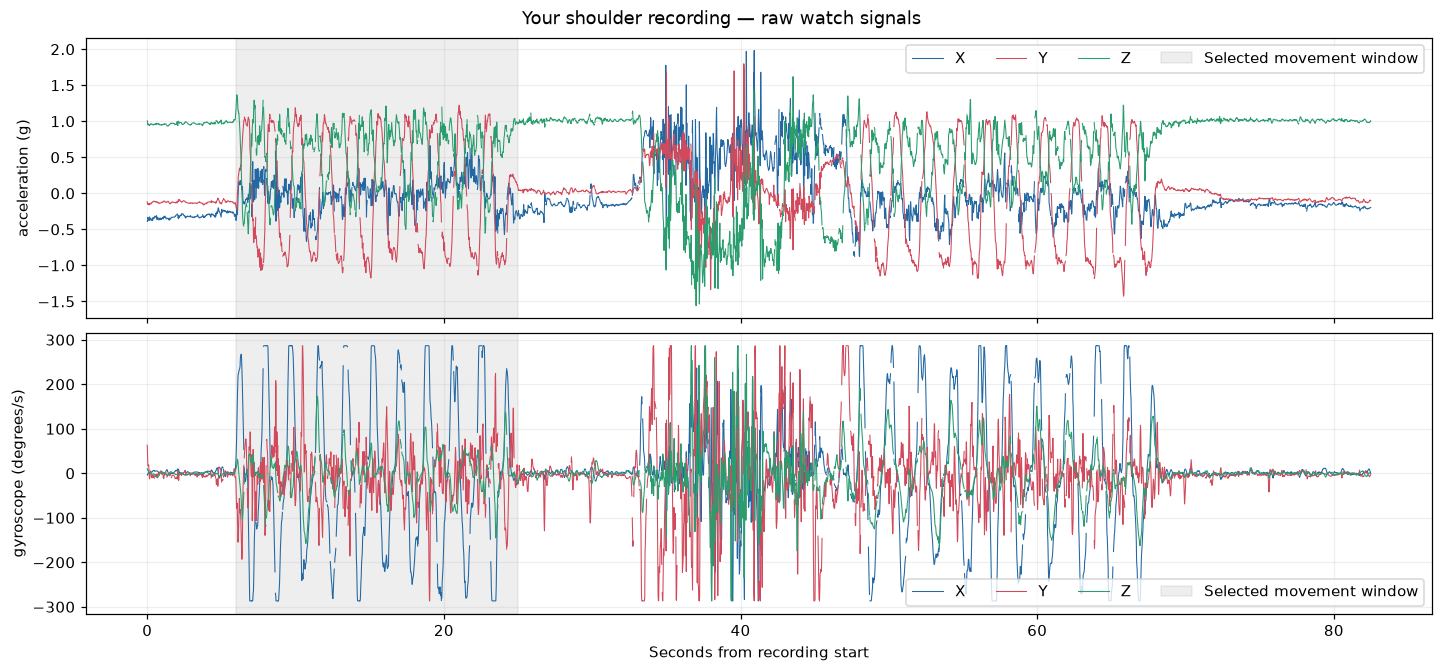

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
for ax, sensor, unit in zip(axes, ['acceleration', 'gyroscope'], ['g', 'degrees/s']):
    a = watch['streams'][sensor]
    y = a[:,1:4].copy()
    y[a[:,4] == 0] = np.nan
    y[np.r_[False, np.diff(a[:,0]) > 0.1]] = np.nan
    for k, color in enumerate(COLORS):
        ax.plot(a[:,0], y[:,k], color=color, linewidth=0.7, label='XYZ'[k])
    ax.axvspan(*WATCH_PLOT_WINDOW, color='#777777', alpha=0.12, label='Selected movement window')
    ax.set_ylabel(f'{sensor} ({unit})'); ax.grid(alpha=0.2); ax.legend(ncol=4)
axes[-1].set_xlabel('Seconds from recording start')
fig.suptitle('Your shoulder recording — raw watch signals')
plt.show()

## 2. Estimate watch orientation for the first wearing period
The existing estimator pairs valid acceleration and gyro samples, bridges gaps up to 60 ms, and resets after longer gaps. It attempts gyro-bias calibration using the first two stationary seconds. It has no absolute heading reference: yaw can drift. Inspect the printed diagnostics.

Angle offsets below are removed **per continuous block** for display. This is not anatomical calibration. Separate blocks are never joined.

In [4]:
def crop(a, interval):
    return a[(a[:,0] >= interval[0]) & (a[:,0] <= interval[1])].copy()

blocks, info = estimate(crop(watch['streams']['acceleration'], WATCH_FUSION_WINDOW),
                        crop(watch['streams']['gyroscope'], WATCH_FUSION_WINDOW), FS)
assert blocks, 'No usable orientation blocks in this interval.'
print(json.dumps(info, indent=2))

def smooth_center(angles):
    smoothed = uniform_filter1d(angles, size=SMOOTH_SAMPLES, axis=0, mode='nearest')
    return smoothed - smoothed[0]

# Unwrap REHAB angles before smoothing to avoid artificial wrap spikes.
rehab_angles = smooth_center(np.rad2deg(np.unwrap(np.deg2rad(rehab), axis=0)))
watch_segments = []
for block in blocks:
    keep = (block['time'] >= WATCH_PLOT_WINDOW[0]) & (block['time'] <= WATCH_PLOT_WINDOW[1])
    if keep.sum() >= 3:
        watch_segments.append((block['time'][keep] - WATCH_PLOT_WINDOW[0],
                               smooth_center(block['angles'][keep])))
assert watch_segments, 'No orientation samples inside the plot window.'
print('Displayed continuous blocks:', len(watch_segments))

{
  "method": "six-axis-gravity-feedback-0.1",
  "status": "experimental_transfer",
  "convention": "body-to-world extrinsic xyz (Rz Ry Rx): roll X, pitch Y, relative yaw Z; output pitch,yaw,roll",
  "yaw_reference": "zero at each continuous block; unobservable absolute heading",
  "sampling_rate_hz": 50.0,
  "max_bridge_sec": 0.06,
  "gravity_feedback_gain_per_sec": 0.5,
  "calibration": "no_stationary_baseline; bias not corrected",
  "gyro_bias_dps": [
    0.0,
    0.0,
    0.0
  ],
  "blocks": 1,
  "notes": [
    "Sensor axes are not calibrated to the REHAB anatomical frame.",
    "Relative yaw can drift; it does not reproduce nine-axis heading.",
    "Dynamic acceleration can disturb tilt; correction gated to 0.85\u20131.15 g.",
    "Long gaps reset orientation; repetitions never cross them."
  ],
  "samples": 1500,
  "interpolated_samples": 349,
  "near_gimbal_samples": 0
}
Displayed continuous blocks: 1


## 3. Compare angles on shared scales
Left: REHAB S1. Right: reconstructed watch orientation. Both use seconds and degrees, identical smoothing, and the same vertical scale for each channel. Starting offsets are removed; amplitudes are preserved. The recordings are not synchronized or matched repetition-by-repetition.

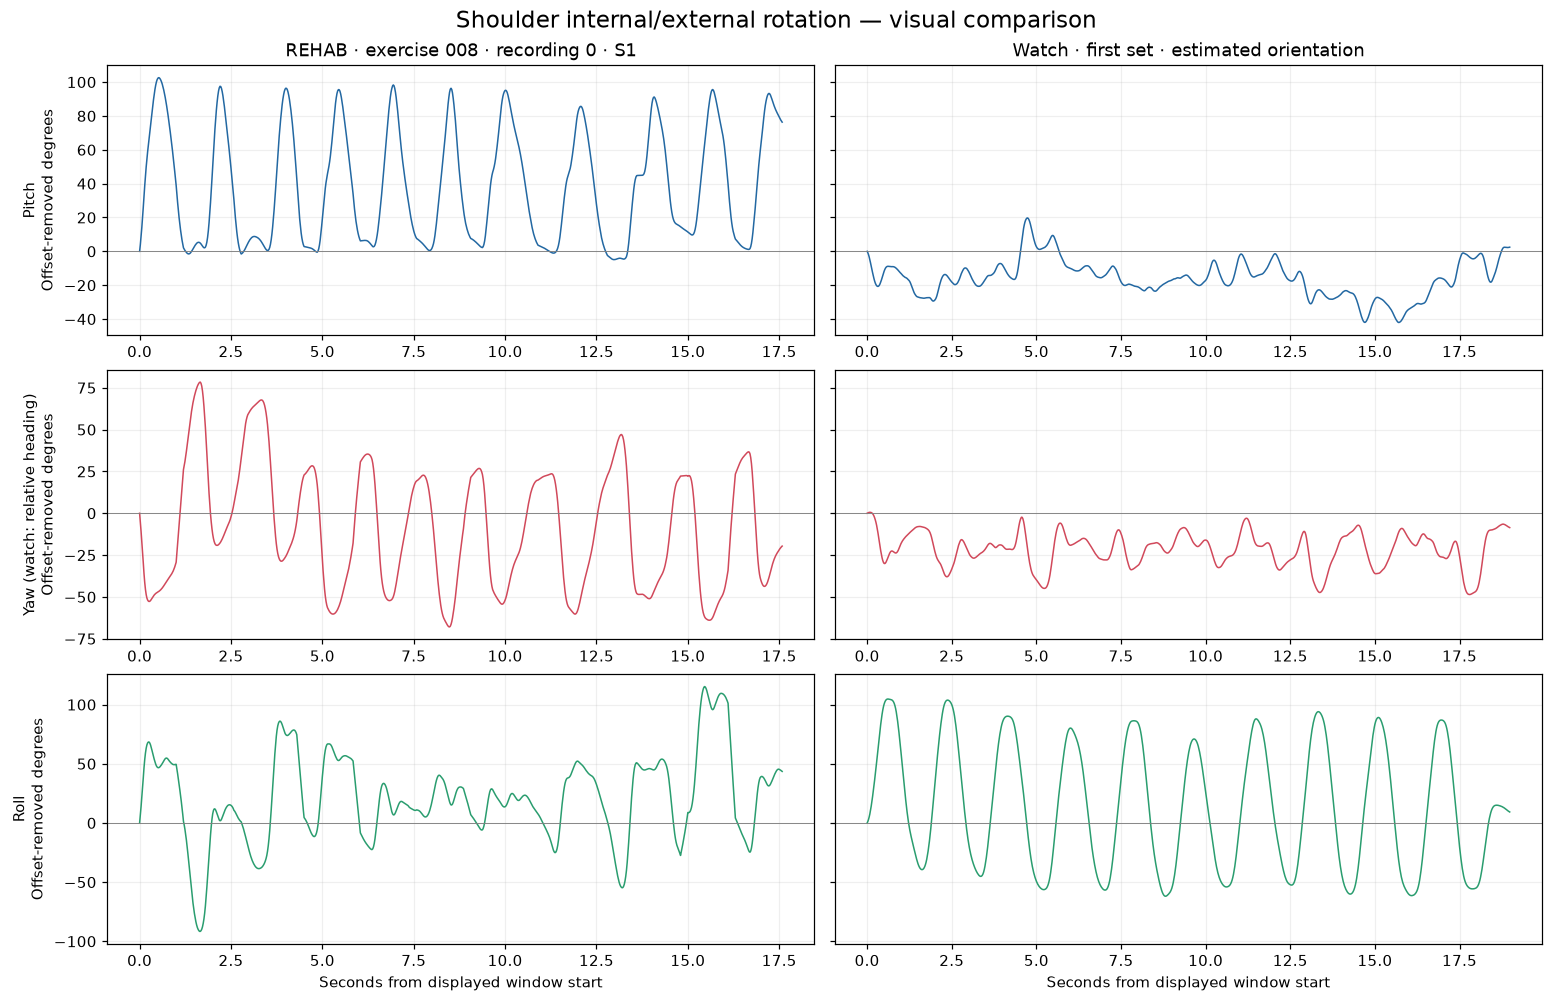

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharey='row', constrained_layout=True)
for k, (name, color) in enumerate(zip(CHANNELS, COLORS)):
    axes[k,0].plot(rehab_t, rehab_angles[:,k], color=color, lw=1)
    for t, angles in watch_segments:
        axes[k,1].plot(t, angles[:,k], color=color, lw=1)
    axes[k,0].set_ylabel(name + '\nOffset-removed degrees')
    for ax in axes[k]:
        ax.grid(alpha=0.2); ax.axhline(0, color='gray', lw=0.6)
axes[0,0].set_title(f'REHAB · exercise 008 · recording {REHAB_RECORDING} · S1')
axes[0,1].set_title('Watch · first set · estimated orientation')
for ax in axes[-1]: ax.set_xlabel('Seconds from displayed window start')
fig.suptitle('Shoulder internal/external rotation — visual comparison', fontsize=15)
plt.show()

## What to look for
- **Repeated shape:** do both signals contain recognizable recurring cycles?
- **Speed:** are cycles closer together in one recording? The time axes retain actual duration, with REHAB assuming 50 Hz.
- **Amplitude and dominant channel:** differences may reflect watch placement, axis convention, fusion error, or execution—not necessarily a technique difference.
- **Drift and clipping:** slowly wandering yaw or flat-topped raw gyro peaks can distort the comparison.

The additional sections below normalize amplitude for visual comparison only and propose candidate cycle boundaries. This notebook does not train or classify. Confirm recording quality and coordinate conventions before interpreting feature differences.

## 4. Check whether the raw gyro reaches its numeric limits
This check reads the original integer gyro values, before smoothing or orientation reconstruction. Repeated values at −32768 or +32767 are consistent with signed 16-bit saturation somewhere in the measurement/export chain. They do not by themselves identify the hardware setting or the cause. We also count samples within 1% of those limits.

The window is the same first movement set used above. Invalid samples are excluded from these percentages. Scaling a clipped signal afterward cannot recover the missing peak information.

Gyro scale in session metadata: 0.00875 degrees/s per raw count
Signed 16-bit endpoints at this scale: -286.72 to 286.71125 degrees/s
Axis | valid samples | exact endpoint hits | near endpoint (%)
X    |           905 |                   0 | 14.03
Y    |           905 |                   0 | 0.44
Z    |           905 |                   0 | 0.00


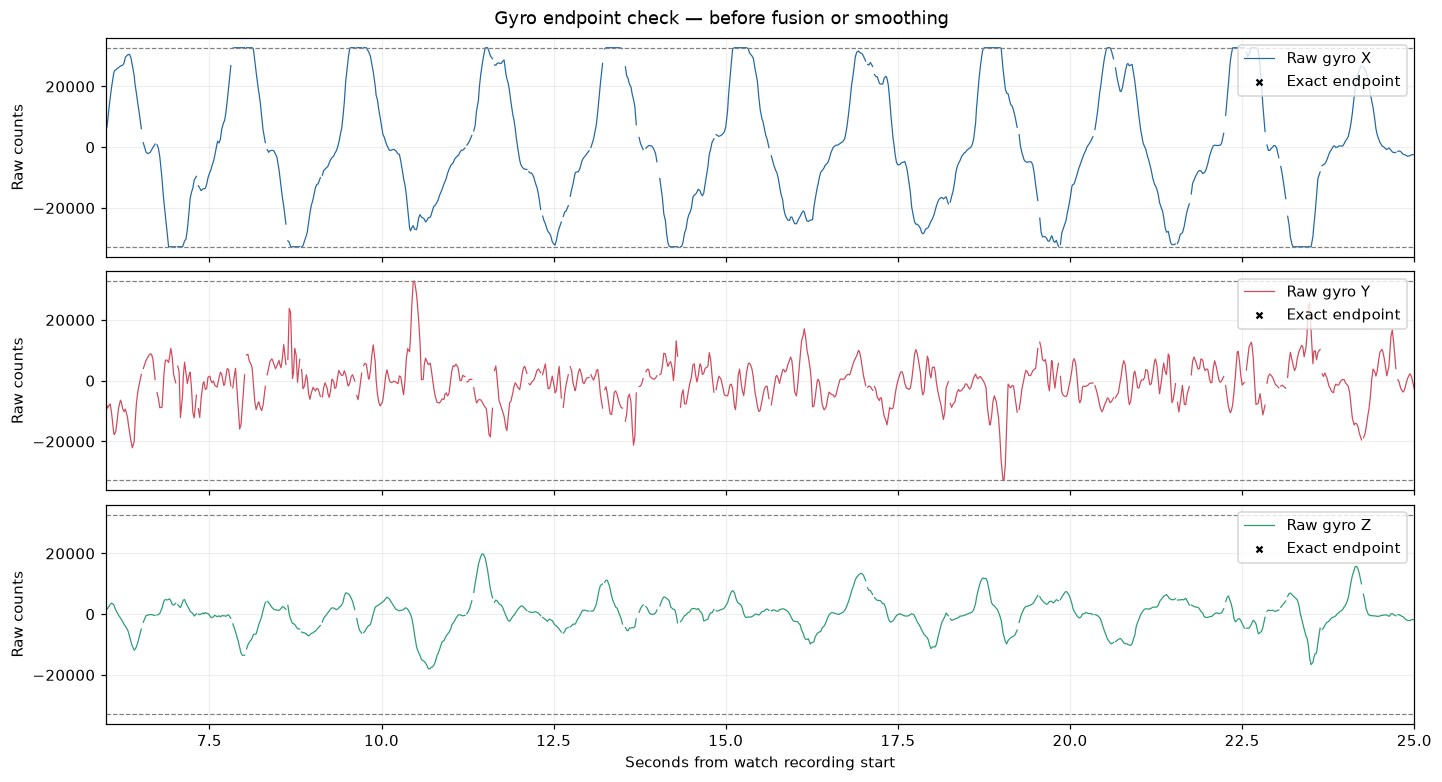

In [6]:
import csv
with WATCH_FILE.open(newline='') as f:
    raw_rows = [r for r in csv.DictReader(f) if r['sensor'] == 'gyroscope']
gyro_stream = watch['streams']['gyroscope']
assert len(raw_rows) == len(gyro_stream)
raw_gyro = np.array([[int(r[k]) for k in ('raw_x', 'raw_y', 'raw_z')] for r in raw_rows])
selected = ((gyro_stream[:,0] >= WATCH_PLOT_WINDOW[0]) &
            (gyro_stream[:,0] <= WATCH_PLOT_WINDOW[1]) & (gyro_stream[:,4] > 0))
assert selected.any(), 'No valid gyro samples in selected window.'
rail_hits = (raw_gyro == -32768) | (raw_gyro == 32767)
near_rail = (raw_gyro <= -0.99*32768) | (raw_gyro >= 0.99*32767)
scale = watch['metadata'].get('raw_scales', {}).get('gyroscope')
print('Gyro scale in session metadata:', scale, 'degrees/s per raw count')
if scale is not None:
    print('Signed 16-bit endpoints at this scale:', -32768*scale, 'to', 32767*scale, 'degrees/s')
print('Axis | valid samples | exact endpoint hits | near endpoint (%)')
for k, name in enumerate('XYZ'):
    print(f'{name:4} | {selected.sum():13} | {rail_hits[selected,k].sum():19} | {100*near_rail[selected,k].mean():.2f}')
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
for k, ax in enumerate(axes):
    t = gyro_stream[:,0]
    y = raw_gyro[:,k].astype(float)
    y[~selected] = np.nan
    y[np.r_[False, np.diff(t) > .1]] = np.nan
    ax.plot(t, y, color=COLORS[k], lw=.8, label='Raw gyro '+ 'XYZ'[k])
    hits = selected & rail_hits[:,k]
    ax.scatter(t[hits], raw_gyro[hits,k], s=15, marker='x', color='black', label='Exact endpoint')
    for limit in (-32768, 32767): ax.axhline(limit, color='gray', ls='--', lw=.8)
    ax.set_ylabel('Raw counts'); ax.grid(alpha=.2); ax.legend(loc='upper right')
axes[-1].set_xlim(*WATCH_PLOT_WINDOW)
axes[-1].set_xlabel('Seconds from watch recording start')
fig.suptitle('Gyro endpoint check — before fusion or smoothing')
plt.show()

## 5. Choose one candidate cycle from each recording
For this exploratory comparison, REHAB **pitch** and watch **roll** are the defaults because they show clear oscillations in the earlier plot. This is a hypothesis about dominant channels, not a calibrated axis mapping.

The helper proposes trough-to-trough cycles using fixed peak-detection settings. It selects the **first** candidate, not the most similar-looking pair. Shaded regions below let you check those choices. Change channel indices, candidate indices, or enter manual windows in the configuration cell. Watch times here are seconds from the displayed window start (add `WATCH_PLOT_WINDOW[0]` to get recording time). Each watch cycle stays inside one continuous orientation block. These boundaries remain provisional.

REHAB candidate intervals: [(1.34, 2.78), (2.78, 4.86), (4.86, 6.4), (6.4, 7.94), (7.94, 9.38), (9.38, 11.32), (11.32, 12.98), (12.98, 15.12), (15.12, 16.66)]
Watch candidates (block, interval): [(0, (1.6210000000000004, 3.3610000000000007)), (0, (3.3610000000000007, 5.221)), (0, (5.221, 7.021000000000001)), (0, (7.021000000000001, 8.821)), (0, (8.821, 10.620999999999999)), (0, (10.620999999999999, 12.541)), (0, (12.541, 14.261)), (0, (14.261, 16.081)), (0, (16.081, 17.881))]


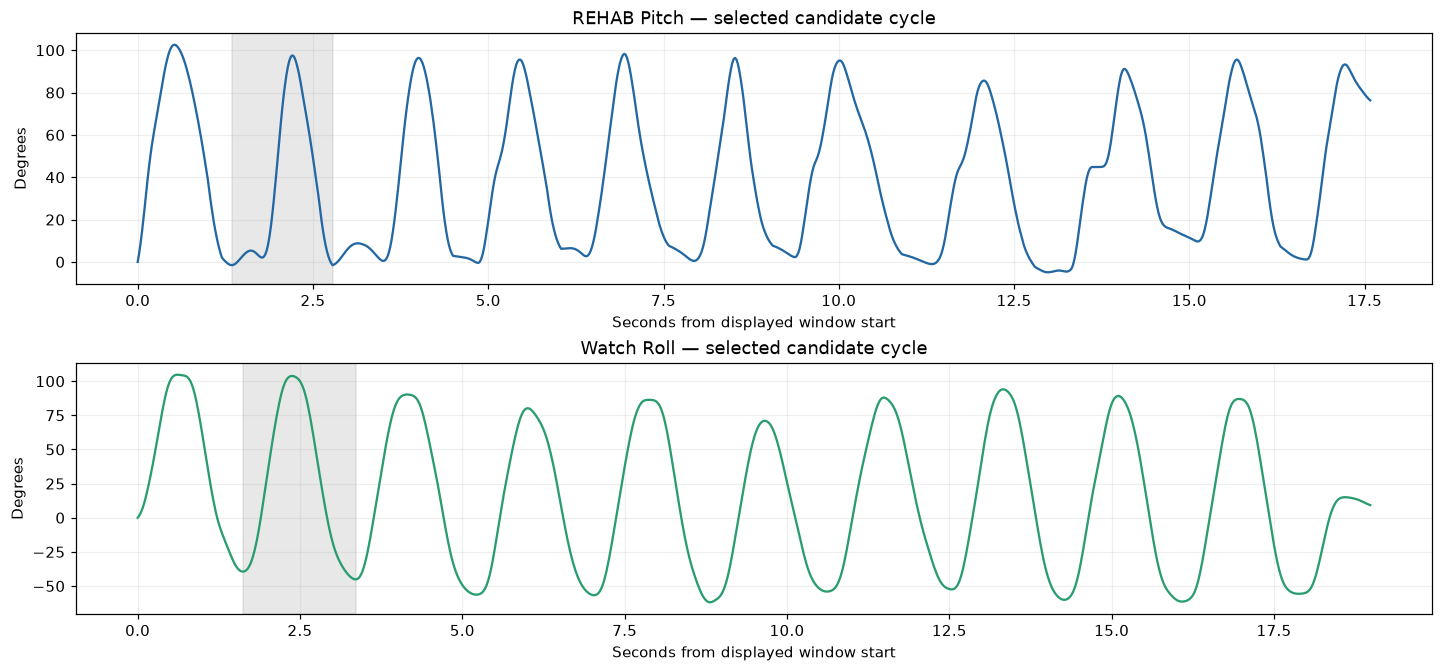

In [7]:
from scipy.signal import find_peaks
REHAB_CHANNEL = 0  # 0 pitch, 1 yaw, 2 roll
WATCH_CHANNEL = 2
REHAB_CYCLE_INDEX = 0
WATCH_CYCLE_INDEX = 0
REHAB_MANUAL_WINDOW = None  # e.g. (start_seconds, end_seconds)
WATCH_MANUAL_WINDOW = None  # relative to WATCH_PLOT_WINDOW start
WATCH_SIGN = 1  # change to -1 ONLY to explore a sign convention; not auto-fitted
MIN_CYCLE_SECONDS = 0.7
MAX_CYCLE_SECONDS = 4.0
PROMINENCE_FRACTION = 0.15
assert WATCH_SIGN in (-1, 1)

def candidates(t, y):
    dt = float(np.median(np.diff(t)))
    amplitude = np.ptp(y)
    if amplitude <= 1e-9: return []
    troughs, _ = find_peaks(-y, distance=max(1,int(MIN_CYCLE_SECONDS/dt)),
                           prominence=PROMINENCE_FRACTION*amplitude)
    return [(float(t[a]), float(t[b])) for a,b in zip(troughs[:-1],troughs[1:])
            if MIN_CYCLE_SECONDS <= t[b]-t[a] <= MAX_CYCLE_SECONDS]

rehab_candidates = candidates(rehab_t, rehab_angles[:,REHAB_CHANNEL])
watch_candidates = [(block_id, interval) for block_id,(t,a) in enumerate(watch_segments)
                    for interval in candidates(t, a[:,WATCH_CHANNEL])]
print('REHAB candidate intervals:', rehab_candidates)
print('Watch candidates (block, interval):', watch_candidates)
if REHAB_MANUAL_WINDOW is None:
    assert len(rehab_candidates) > REHAB_CYCLE_INDEX, 'Set a manual REHAB window or adjust detection.'
    r_window = rehab_candidates[REHAB_CYCLE_INDEX]
else: r_window = REHAB_MANUAL_WINDOW
if WATCH_MANUAL_WINDOW is None:
    assert len(watch_candidates) > WATCH_CYCLE_INDEX, 'Set a manual watch window or adjust detection.'
    w_block, w_window = watch_candidates[WATCH_CYCLE_INDEX]
else:
    w_window = WATCH_MANUAL_WINDOW
    matches = [i for i,(t,a) in enumerate(watch_segments) if t[0] <= w_window[0] < w_window[1] <= t[-1]]
    assert len(matches) == 1, 'Manual watch window must lie inside one continuous block.'
    w_block = matches[0]
assert rehab_t[0] <= r_window[0] < r_window[1] <= rehab_t[-1]
wt, wa = watch_segments[w_block]
r_keep = (rehab_t >= r_window[0]) & (rehab_t <= r_window[1])
w_keep = (wt >= w_window[0]) & (wt <= w_window[1])
rt, ry = rehab_t[r_keep], rehab_angles[r_keep, REHAB_CHANNEL]
ct, cy = wt[w_keep], wa[w_keep, WATCH_CHANNEL]
assert len(rt) >= 5 and len(ct) >= 5
fig, axes = plt.subplots(2,1,figsize=(13,6),constrained_layout=True)
axes[0].plot(rehab_t, rehab_angles[:,REHAB_CHANNEL], color=COLORS[REHAB_CHANNEL])
for t,a in watch_segments: axes[1].plot(t,a[:,WATCH_CHANNEL], color=COLORS[WATCH_CHANNEL])
for ax, window, title in zip(axes,[r_window,w_window],
    ['REHAB '+CHANNELS[REHAB_CHANNEL], 'Watch '+CHANNELS[WATCH_CHANNEL]]):
    ax.axvspan(*window, alpha=.18, color='gray');ax.set_title(title+' — selected candidate cycle')
    ax.set_ylabel('Degrees');ax.set_xlabel('Seconds from displayed window start');ax.grid(alpha=.2)
plt.show()

## 6. Separate timing, amplitude, and sign effects
**Left:** elapsed seconds and degrees, with only each cycle's starting offset removed. This preserves measured duration and angular excursion.

**Middle:** stretch each cycle to 0–100% cycle time, retaining degrees. This removes speed differences from the display.

**Right:** additionally scale each cycle to 0–1 using its own minimum and maximum. This removes amplitude and offset differences, revealing shape. The optional watch sign flip is stated in the legend and applies only to the shape panel.

A closer match after scaling does not validate the axis mapping, restore clipped data, or prove that both exercises were executed identically. Euler angles cannot generally be anatomically aligned by swapping columns; that needs sensor-frame calibration and the underlying rotation conventions.

REHAB: duration 1.44 s; channel excursion 99.1 degrees
Watch: duration 1.74 s; estimated channel excursion 148.9 degrees
Channel excursion is not an anatomical joint range-of-motion measurement.
Selected watch cycle: valid gyro samples with any exact endpoint: 0 of 82


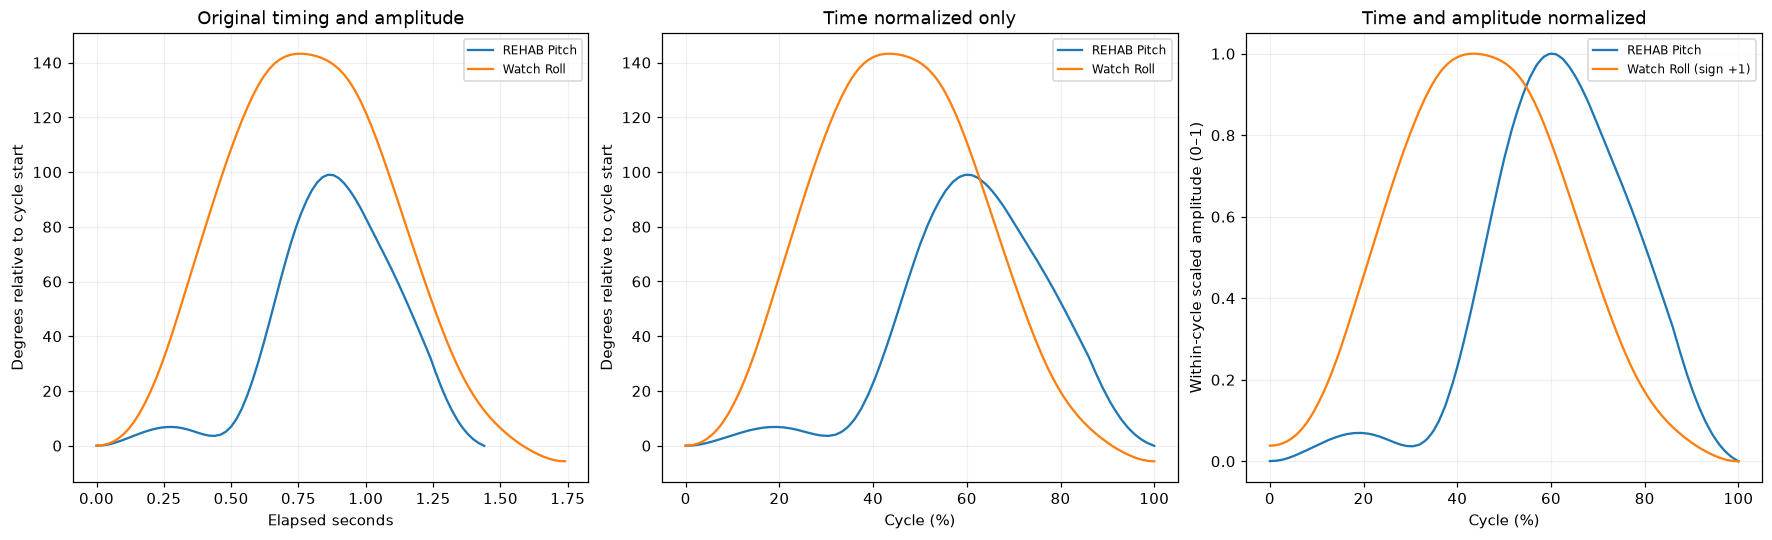

In [8]:
phase = np.linspace(0, 1, 201)
r_phase = (rt-rt[0])/(rt[-1]-rt[0]); w_phase = (ct-ct[0])/(ct[-1]-ct[0])
r_curve = np.interp(phase, r_phase, ry); w_curve = np.interp(phase, w_phase, cy)
def minmax(y):
    span = np.ptp(y)
    if span < 1e-9: raise ValueError('Cannot normalize a constant cycle.')
    return (y-y.min())/span
r_label = 'REHAB '+CHANNELS[REHAB_CHANNEL]
w_label = 'Watch '+CHANNELS[WATCH_CHANNEL]
fig, axes = plt.subplots(1,3,figsize=(16,4.8),constrained_layout=True)
axes[0].plot(rt-rt[0],ry-ry[0],label=r_label)
axes[0].plot(ct-ct[0],cy-cy[0],label=w_label)
axes[0].set(xlabel='Elapsed seconds',ylabel='Degrees relative to cycle start',title='Original timing and amplitude')
axes[1].plot(phase*100,r_curve-r_curve[0],label=r_label)
axes[1].plot(phase*100,w_curve-w_curve[0],label=w_label)
axes[1].set(xlabel='Cycle (%)',ylabel='Degrees relative to cycle start',title='Time normalized only')
axes[2].plot(phase*100,minmax(r_curve),label=r_label)
axes[2].plot(phase*100,minmax(WATCH_SIGN*w_curve),label=w_label+f' (sign {WATCH_SIGN:+d})')
axes[2].set(xlabel='Cycle (%)',ylabel='Within-cycle scaled amplitude (0–1)',title='Time and amplitude normalized')
for ax in axes: ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.show()
print(f'REHAB: duration {rt[-1]-rt[0]:.2f} s; channel excursion {np.ptp(ry):.1f} degrees')
print(f'Watch: duration {ct[-1]-ct[0]:.2f} s; estimated channel excursion {np.ptp(cy):.1f} degrees')
print('Channel excursion is not an anatomical joint range-of-motion measurement.')
cycle_raw = selected & (gyro_stream[:,0] >= ct[0]+WATCH_PLOT_WINDOW[0]) & (gyro_stream[:,0] <= ct[-1]+WATCH_PLOT_WINDOW[0])
print('Selected watch cycle: valid gyro samples with any exact endpoint:',
      int(rail_hits[cycle_raw].any(axis=1).sum()), 'of', int(cycle_raw.sum()))

### How to use the result
- If endpoint hits occur, inspect gyro range, firmware conversion, and raw logging before treating reconstructed angle amplitude as reliable. Existing data can still support exploratory visualization.
- If shape looks closer only after changing channels, investigate placement and coordinate frames rather than applying a scaler to fix axes.
- If the time-normalized comparison is close but amplitude differs, assess sensor calibration and movement range before fitting any feature scaler.
- Repeat the comparison across multiple candidate cycles and participants. A single selected pair is an illustration, not a validation result.

All normalization here is for plotting. No training scaler, classifier, or source recording is changed.

## 7. Compatibility audit — before pooling the 17 features
Goal: use watch and REHAB repetitions together without disguising coordinate differences as movement differences.

Evidence checked:
- [REHAB paper, equations 4–6](https://www.nature.com/articles/s41597-026-07802-2): quaternion-to-angle equations are provided. **As printed**, the roll denominator differs from the standard extrinsic xyz expression used by the watch estimator. This may be a publication typo; it is not proof that the saved dataset used that formula.
- [Author preprocessing code](https://github.com/zzzzz-123/REHAB/blob/main/Rehab_training/data_upload.py): concatenates existing processed arrays; this file does not implement orientation estimation or resolve the equation discrepancy.
- Watch estimator: SciPy extrinsic xyz; outputs pitch, relative yaw, roll. No magnetometer; absolute heading is unavailable.
- The project's existing 17 features are axis dependent. Starting-offset subtraction and StandardScaler do not remove mounting rotations.

The calculations below test the discrepancy and audit starting poses. They **do not** impose an unverified conversion on the recordings.

In [9]:
from scipy.spatial.transform import Rotation
# Quaternion order from SciPy: x,y,z,w. Paper names its scalar m, then w'.
# The printed roll denominator is w²+x²-y²-z²; standard xyz uses w²-x²-y²+z².
test_rolls = np.array([0., 30., 60., 90.])
q = Rotation.from_euler('x', test_rolls[:, None], degrees=True).as_quat()
x,y,z,w = q.T
printed_roll = np.rad2deg(np.arctan2(2*(y*z+w*x), w*w+x*x-y*y-z*z))
standard_roll = np.rad2deg(np.arctan2(2*(y*z+w*x), w*w-x*x-y*y+z*z))
assert np.allclose(standard_roll, test_rolls)
print('Known rotation | standard roll | paper formula as printed')
for angle,a,b in zip(test_rolls,standard_roll,printed_roll):
    print(f'{angle:14.1f} | {a:13.1f} | {b:24.1f}')
print('This establishes a formula discrepancy, not which formula generated REHAB.')

Known rotation | standard roll | paper formula as printed
           0.0 |           0.0 |                      0.0
          30.0 |          30.0 |                     26.6
          60.0 |          60.0 |                     40.9
          90.0 |          90.0 |                     45.0
This establishes a formula discrepancy, not which formula generated REHAB.


### Starting-hold evidence for every shoulder recording
Use the first five recording seconds as a **candidate** neutral hold. Report valid paired samples, per-axis acceleration variability, angular-speed magnitude, and the mean gravity direction. These are diagnostics, not an automatic calibration pass.

Gravity gives one direction (tilt). It cannot identify rotation about gravity, so even a stationary hold cannot determine the full sensor-to-arm alignment. Differences between gravity vectors can also come from different arm poses. The second attachment needs its own reviewed hold; this audit does not guess its timing.

In [10]:
shoulder_audit = []
for path in sorted(WATCH_FILE.parent.glob('*.csv')):
    metadata = json.loads(path.with_suffix('.json').read_text())
    if metadata.get('homestretch',{}).get('exercise_id') != 'shoulder_internal_external_rotation':
        continue
    record = load_recording(path)
    a = crop(record['streams']['acceleration'], (0,5))
    g = crop(record['streams']['gyroscope'], (0,5))
    _,ai,gi = np.intersect1d(a[:,0],g[:,0],return_indices=True)
    a,g = a[ai],g[gi]
    ok = (a[:,4]>0)&(g[:,4]>0)&np.isfinite(a[:,1:4]).all(axis=1)&np.isfinite(g[:,1:4]).all(axis=1)
    av,gv = a[ok,1:4],g[ok,1:4]
    row = dict(file=path.name,paired_samples=len(a),valid_pairs=int(ok.sum()),
               second_attachment='not yet reviewed',full_alignment='unresolved')
    if len(av)>=2:
        gravity = av.mean(axis=0)
        row.update(accel_std_max_g=float(av.std(axis=0).max()),
                   gyro_speed_p95_dps=float(np.percentile(np.linalg.norm(gv,axis=1),95)),
                   mean_accel_magnitude_g=float(np.linalg.norm(av,axis=1).mean()),
                   gravity_direction=(gravity/np.linalg.norm(gravity)).round(4).tolist(),
                   max_valid_gap_sec=float(np.diff(a[ok,0]).max()))
    shoulder_audit.append(row)
for row in shoulder_audit:
    print(row['file'])
    print(json.dumps({k:v for k,v in row.items() if k!='file'},indent=2))
print('Audited shoulder recordings:',len(shoulder_audit))

Anisha shoulder left_20261005-120401_52aa17ba.csv
{
  "paired_samples": 250,
  "valid_pairs": 237,
  "second_attachment": "not yet reviewed",
  "full_alignment": "unresolved",
  "accel_std_max_g": 0.028419554073261778,
  "gyro_speed_p95_dps": 18.10282238310647,
  "mean_accel_magnitude_g": 1.02762571102043,
  "gravity_direction": [
    -0.3134,
    -0.122,
    0.9417
  ],
  "max_valid_gap_sec": 0.04500000000000004
}
angel shoulder left_20261005-122351_c31f0291.csv
{
  "paired_samples": 250,
  "valid_pairs": 234,
  "second_attachment": "not yet reviewed",
  "full_alignment": "unresolved",
  "accel_std_max_g": 0.013273735099998454,
  "gyro_speed_p95_dps": 6.811113703891141,
  "mean_accel_magnitude_g": 1.020390053247956,
  "gravity_direction": [
    0.3999,
    -0.0089,
    0.9165
  ],
  "max_valid_gap_sec": 0.04300000000000004
}
arshaan shoulder left_20261005-123919_af218ecb.csv
{
  "paired_samples": 250,
  "valid_pairs": 237,
  "second_attachment": "not yet reviewed",
  "full_alignment":

### What conversion would be valid once the frame convention is resolved?
Let `R_WS(t)` map watch-sensor coordinates into world coordinates, and let `C` map a chosen common forearm frame into watch-sensor coordinates. Then:

`R_WB(t) = R_WS(t) @ C`

Relative to a neutral pose:

`R_relative(t) = (R_WS(0) @ C).T @ (R_WS(t) @ C)`

Only then convert the rotation to a **verified common Euler convention**. Apply the same reference convention to REHAB before recomputing both feature sets. Existing trained models cannot be assumed compatible after changing the representation.

A neutral reference removes global starting orientation, but the unknown mounting matrix C remains. Setting C to identity silently assumes alignment. Choosing C to make an unrelated REHAB cycle look similar is not calibration.

**Current decision:** pooled training is not ready. Units, channel ordering in our loader, and the computational watch convention are known; the REHAB implementation convention and full sensor-to-common-frame alignment remain unresolved. Existing recordings are retained for analysis.

**Specific information needed:** the REHAB quaternion-to-angle implementation (or corrected equations and axis/zero-pose definition), plus watch attachment directions or a known calibration movement for each wearing period. A neutral hold alone does not supply the missing heading. The files inspected here do not contain an explicit mounting rotation. Do not replace this missing information with an axis swap or a fitted scaler.